In [53]:
import warnings
warnings.filterwarnings('ignore')

In [54]:
import matplotlib.pyplot as plt
import math
import json
import numpy as np
import torch
import pickle
import torch.nn as nn
import pandas as pd
import seaborn as sns
import torch.optim as optim
import torch.nn.functional as F
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from matplotlib.pyplot import scatter, figure
from scipy import stats
from numpy.ma.core import outer
from sys import stderr


In [55]:
start = -np.pi/2
end = np.pi/2
n = 300
batch_size = 16
modelSamples = 50

In [56]:
# Define the Ishigami function
def ishigami_function(x1, x2, x3, a=7, b=0.1):
    return np.sin(x1) + a * np.sin(x2)**2 + b * x3**4 * np.sin(x1)

# Generate Ishigami dataset with added variance
def generate_ishigami_dataset(start, end, n_samples):
    np.random.seed(0)
    x1 = np.random.uniform(start, end, n_samples)
    x2 = np.random.uniform(start, end, n_samples)
    x3 = np.random.uniform(start, end, n_samples)
    f_x = ishigami_function(x1, x2, x3)
    # Add variance to y
    y_var = 0.2
    y = np.random.normal(f_x, y_var, n_samples)
    return x1, x2, x3, y



In [57]:
x1, x2, x3, y = generate_ishigami_dataset(start, end, n)

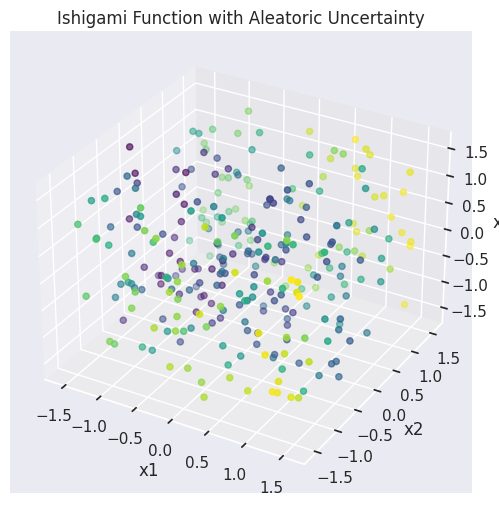

In [58]:
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(x1, x2, x3, c=y, cmap='viridis')
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('x3')
ax.set_title('Ishigami Function with Aleatoric Uncertainty')
plt.show()

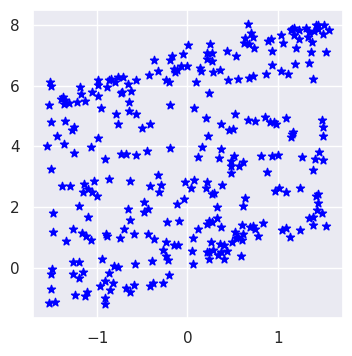

In [59]:

x1_train, y_train = x1,y
scatter(x1_train, y_train, c="blue", marker="*")

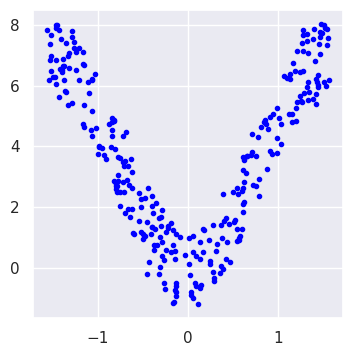

In [60]:
x2_train, y_train = x2,y
scatter(x2_train, y_train, c="blue", marker=".")

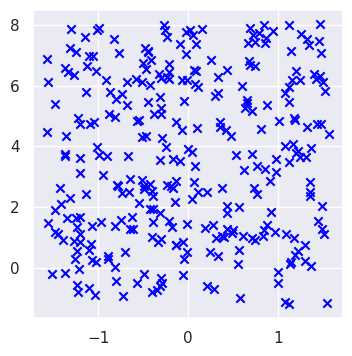

In [61]:
x3_train, y_train = x3,y
scatter(x3_train, y_train, c="blue", marker="x")

In [62]:
figure(figsize=(4, 4))
# Not exactely the same distribution, but works for now
x1_test, x2_test,x3_test, y_test = generate_ishigami_dataset(-np.pi, np.pi, 200)


<Figure size 400x400 with 0 Axes>

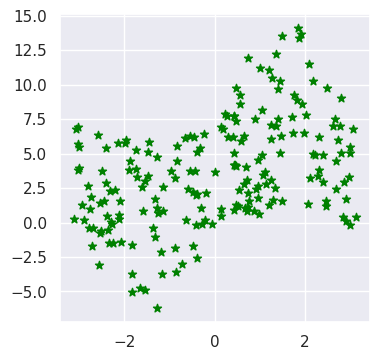

In [63]:
scatter(x1_test, y_test, c="green", marker="*")

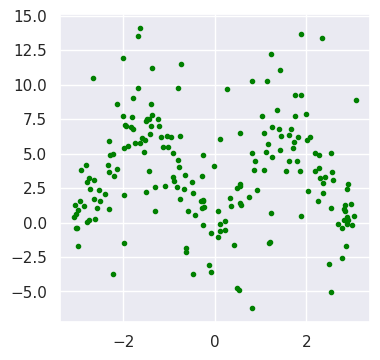

In [64]:
scatter(x2_test, y_test, c="green", marker=".")

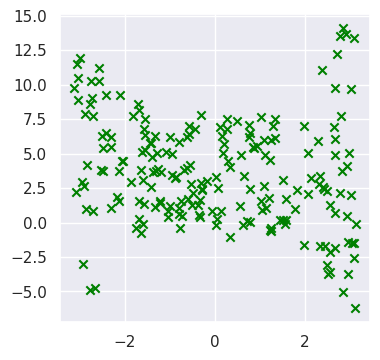

In [65]:
scatter(x3_test, y_test, c="green", marker="x")

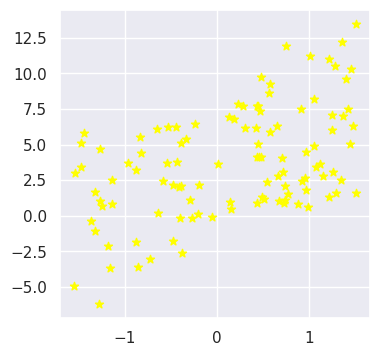

In [66]:
#Plotting In Training Distribution Data Points in the Test Set
# Filter the data to retain only the desired ranges
mask_x1_test_idd =  (x1_test >= start) &  (x1_test <= end) # Select the ranges -pi/2 to pi/2
x1_test_idd = x1_test[mask_x1_test_idd]
y_test_idd = y_test[mask_x1_test_idd]

plt.figure(figsize=(4, 4))
plt.scatter(x1_test_idd, y_test_idd, c="yellow", marker="*")

plt.show()


In [67]:
# mask_x2_test_idd =  (x2_test >= start) &  (x2_test <= end) # Select the ranges -pi/2 to pi/2
# x2_test_idd = x2_test[mask_x2_test_idd]
# y_test_idd = y_test[mask_x2_test_idd]

# plt.figure(figsize=(4, 4))
# plt.scatter(x2_test_idd, y_test_idd, c="yellow", marker=".")

# plt.show()

In [68]:
# mask_x3_test_idd =  (x3_test >= start) &  (x3_test <= end) # Select the ranges -pi/2 to pi/2
# x3_test_idd = x3_test[mask_x3_test_idd]
# y_test_idd = y_test[mask_x3_test_idd]

# plt.figure(figsize=(4, 4))
# plt.scatter(x3_test_idd, y_test_idd, c="yellow", marker="x")

# plt.show()

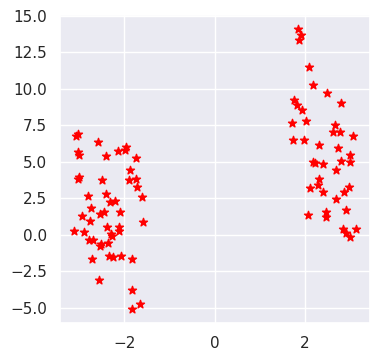

In [69]:
#Plotting Out of Training Distribution Data Points in the Test Set
# Filter the data to retain only the desired ranges
mask_x1_test_oodd = (x1_test >= -np.pi) & (x1_test < start) | (x1_test > end) & (x1_test <= np.pi) # Select the ranges -pi to -pi/2 and pi/2 to pi
x1_test_oodd = x1_test[mask_x1_test_oodd]
y_test_oodd = y_test[mask_x1_test_oodd]

plt.figure(figsize=(4, 4))
plt.scatter(x1_test_oodd, y_test_oodd, c="red", marker="*")

plt.show()


In [70]:
# mask_x2_test_oodd = (x2_test >= -np.pi) & (x2_test < start) | (x2_test > end) & (x2_test <= np.pi) # Select the ranges -pi to -pi/2 and pi/2 to pi
# x2_test_oodd = x2_test[mask_x2_test_oodd]
# y_test_oodd = y_test[mask_x2_test_oodd]

# plt.figure(figsize=(4, 4))
# plt.scatter(x2_test_oodd, y_test_oodd, c="red", marker=".")

# plt.show()

In [71]:
# mask_x3_test_oodd = (x3_test >= -np.pi) & (x3_test < start) | (x3_test > end) & (x3_test <= np.pi) # Select the ranges -pi to -pi/2 and pi/2 to pi
# x3_test_oodd = x3_test[mask_x3_test_oodd]
# y_test_oodd = y_test[mask_x3_test_oodd]

# plt.figure(figsize=(4, 4))
# plt.scatter(x3_test_oodd, y_test_oodd, c="red", marker="x")

# plt.show()

In [72]:


# Train
tensor_x = torch.Tensor(x1_train).unsqueeze(1)
tensor_y = torch.Tensor(y_train).unsqueeze(1)
train_dataset = TensorDataset(tensor_x, tensor_y)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

#Test for OODD (Out of Data Distribution)
tensor_x_test_oodd = torch.Tensor(x1_test_oodd).unsqueeze(1)
tensor_y_test_oodd = torch.Tensor(y_test_oodd).unsqueeze(1)
test_dataset_oodd = TensorDataset(tensor_x_test_oodd, tensor_y_test_oodd)
test_loader_oodd = DataLoader(test_dataset_oodd, batch_size=batch_size, shuffle=True)

# #Test for IDD (In Data Distribution)
tensor_x_test_idd = torch.Tensor(x1_test_idd).unsqueeze(1)
tensor_y_test_idd = torch.Tensor(y_test_idd).unsqueeze(1)
test_dataset_idd = TensorDataset(tensor_x_test_idd, tensor_y_test_idd)
test_loader_idd = DataLoader(test_dataset_idd, batch_size=batch_size, shuffle=True)

# Test
tensor_x_test = torch.Tensor(x1_test).unsqueeze(1)
tensor_y_test = torch.Tensor(y_test).unsqueeze(1)
test_dataset = TensorDataset(tensor_x_test, tensor_y_test)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=True)

In [73]:
class SimpleNet(nn.Module):
    def __init__(self):
        super(SimpleNet, self).__init__()
        hidden_size = 60

        # We only have 1 input feature
        self.fc1 = nn.Linear(1, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.mu = nn.Linear(hidden_size, 1)
        self.var = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h = torch.tanh(self.fc1(x))
        h = torch.tanh(self.fc2(h))
        mu = self.mu(h)
        # Exponential activation to enforce positive var
        # Arash: this might be a significant difference:
        var = torch.exp(self.var(h))
        return mu, var



In [74]:

def plot_with_confidence_interval(model, tensor_x_test, tensor_y_test, x_test,y_test,color,start, end):
    sns.set(rc={'figure.figsize': (4, 4)})

    # Get predictions
    mu, var = model(tensor_x_test)
    mu, sigma = mu.detach().numpy(), var.detach().numpy()**(1/2)

    # Calculate the 95% confidence interval
    lower_bound = mu - 2 * sigma
    upper_bound = mu + 2 * sigma

    # Count the data points within the confidence interval
    count_within_ci = np.sum((tensor_y_test.numpy() >= lower_bound) & (tensor_y_test.numpy() <= upper_bound))
    percentage_count_within_ci = (count_within_ci / tensor_y_test.shape[0]) * 100
    print(f'Number of data points within the 95% confidence interval: {count_within_ci}')
    print(f'Percentage of data points within the 95% confidence interval: {percentage_count_within_ci}')

    # ~ 95% conf. interval (see https://en.wikipedia.org/wiki/1.96)
    y_vals = [mu, mu + 2 * sigma, mu - 2 * sigma]
    dfs = []

    # Create DF from predictions
    for i in range(3):
        data = {
            "x": list(tensor_x_test.squeeze().numpy()),
            "y": list(y_vals[i].squeeze())
        }
        temp = pd.DataFrame.from_dict(data)
        dfs.append(temp)
    df = pd.concat(dfs).reset_index()

    # Plot predictions with confidence
    sns_plot = sns.lineplot(data=df, x="x", y="y")

    # Highlight training range
    plt.axvline(x=start)
    plt.axvline(x=end)

    # Plot test data on top
    scatter(x_test, y_test, c=color, marker="*", alpha=0.5)
    plt.show()
    return percentage_count_within_ci


In [75]:


def train_and_evaluate_net(net, train_loader, test_loader, tensor_x_test, tensor_y_test,  x_test,y_test,color,num_epochs=150, learning_rate=0.001):
    # Define loss and optimizer
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    criterion = torch.nn.GaussianNLLLoss(eps=1e-02)
    optimizer = optim.Adam(net.parameters(), lr=learning_rate)
    net.train()
    net.to(device)

    for epoch in range(num_epochs):
        # Train loop
        for batch in train_loader:
            x, y = batch[0].to(device), batch[1].to(device)
            optimizer.zero_grad()
            mu, var = net(x)
            loss = criterion(mu, y, var)
            loss.backward()
            optimizer.step()
            criterionmse_train = nn.MSELoss()
            mse_train = criterionmse_train(mu, y)
        if epoch % 10 == 0:
            all_test_losses = []
            all_mse_test = []
            # Test loop
            for batch in test_loader:
                x, y = batch[0].to(device), batch[1].to(device)
                mu, var = net(x)
                all_test_losses.append(criterion(mu, y, var).item())
                criterionmse_test = nn.MSELoss()
                all_mse_test.append(criterionmse_test(mu, y).item())
            test_loss = sum(all_test_losses) / len(all_test_losses)
            test_mse = sum(all_mse_test) / len(all_mse_test)
    percentage_count_within_ci=plot_with_confidence_interval(net, tensor_x_test, tensor_y_test,x_test,y_test,color,start, end)
    return loss, test_loss, mse_train, test_mse,net,percentage_count_within_ci

def Neural_Network(net,train_loader,test_loader,tensor_x_test,tensor_y_test, x_test,y_test,color):
    loss, test_loss, mse_train, test_mse,net,percentage_count_within_ci = train_and_evaluate_net(net, train_loader, test_loader,tensor_x_test,tensor_y_test, x_test,y_test,color)
    return loss, test_loss, mse_train, test_mse,net,percentage_count_within_ci



In [76]:

# Example JSON string
json_str = '''
{
  "test_loaders": ["test_loader", "test_loader_oodd", "test_loader_idd"],
  "test_tensors_x":["tensor_x_test","tensor_x_test_oodd","tensor_x_test_idd"],
  "test_tensors_y":["tensor_y_test","tensor_y_test_oodd","tensor_y_test_idd"],
  "color":["green","red","yellow"],
  "testset_x":["x_test","x_test_oodd","x_test_idd"],
  "testset_y":["y_test","y_test_oodd","y_test_idd"],
  "output_dirs": ["pickled_models_", "pickled_models_oodd_", "pickled_models_idd_"],
  "error_metrics":["em","em_oodd","em_idd"]
}
'''

# Parse JSON
data = json.loads(json_str)

# Map string names to actual variables
test_loader_vars = {
    "test_loader": test_loader,
    "test_loader_oodd": test_loader_oodd,
    "test_loader_idd": test_loader_idd
}
tensor_x_mapping = {
    "tensor_x_test": tensor_x_test,
    "tensor_x_test_oodd": tensor_x_test_oodd,
    "tensor_x_test_idd": tensor_x_test_idd
}

tensor_y_mapping = {
    "tensor_y_test": tensor_y_test,
    "tensor_y_test_oodd": tensor_y_test_oodd,
    "tensor_y_test_idd": tensor_y_test_idd
}
testset_x_mapping = {
    "x_test": x1_test,
    "x_test_oodd": x1_test_oodd,
    "x_test_idd": x1_test_idd
}

# Mapping from string names to actual variables for testset_y
testset_y_mapping = {
    "y_test": y_test,
    "y_test_oodd": y_test_oodd,
    "y_test_idd": y_test_idd
}

# Access corresponding values using a loop
test_loaders = data["test_loaders"]
test_tensors_x=data["test_tensors_x"]
test_tensors_y=data["test_tensors_y"]
color=data["color"]
testset_x=data["testset_x"]
testset_y=data["testset_y"]
output_dirs = data["output_dirs"]
error_mets=data["error_metrics"]



Number of data points within the 95% confidence interval: 172
Percentage of data points within the 95% confidence interval: 86.0


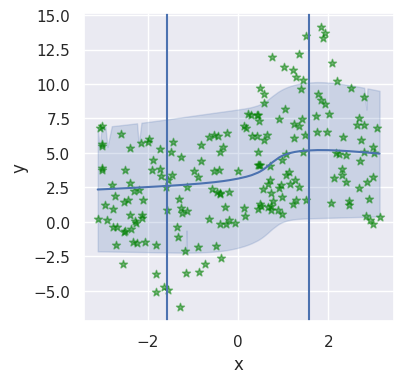

Number of data points within the 95% confidence interval: 170
Percentage of data points within the 95% confidence interval: 85.0


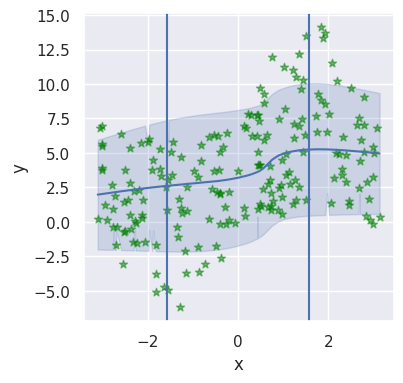

Number of data points within the 95% confidence interval: 170
Percentage of data points within the 95% confidence interval: 85.0


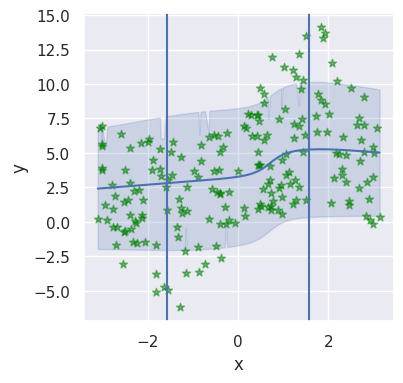

Number of data points within the 95% confidence interval: 170
Percentage of data points within the 95% confidence interval: 85.0


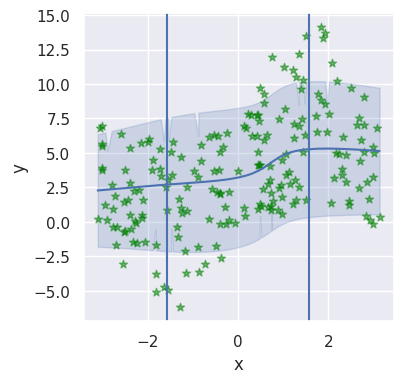

Number of data points within the 95% confidence interval: 172
Percentage of data points within the 95% confidence interval: 86.0


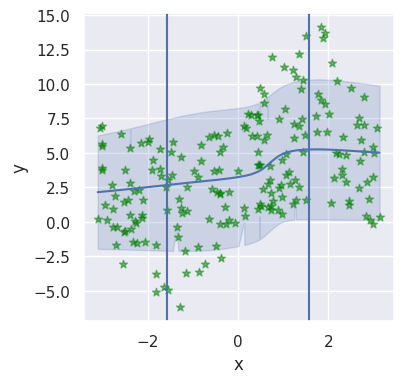

Number of data points within the 95% confidence interval: 170
Percentage of data points within the 95% confidence interval: 85.0


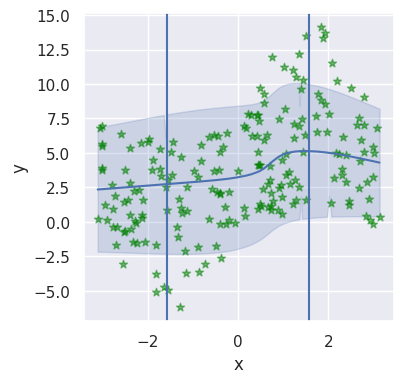

Number of data points within the 95% confidence interval: 171
Percentage of data points within the 95% confidence interval: 85.5


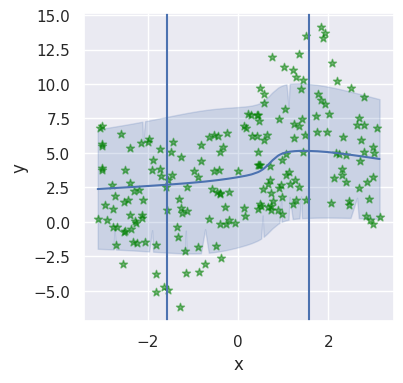

Number of data points within the 95% confidence interval: 170
Percentage of data points within the 95% confidence interval: 85.0


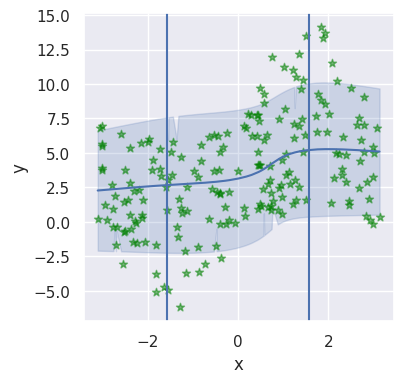

Number of data points within the 95% confidence interval: 172
Percentage of data points within the 95% confidence interval: 86.0


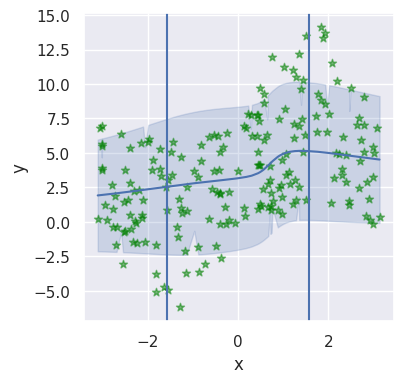

Number of data points within the 95% confidence interval: 169
Percentage of data points within the 95% confidence interval: 84.5


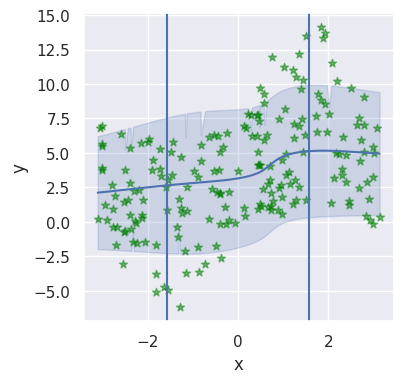

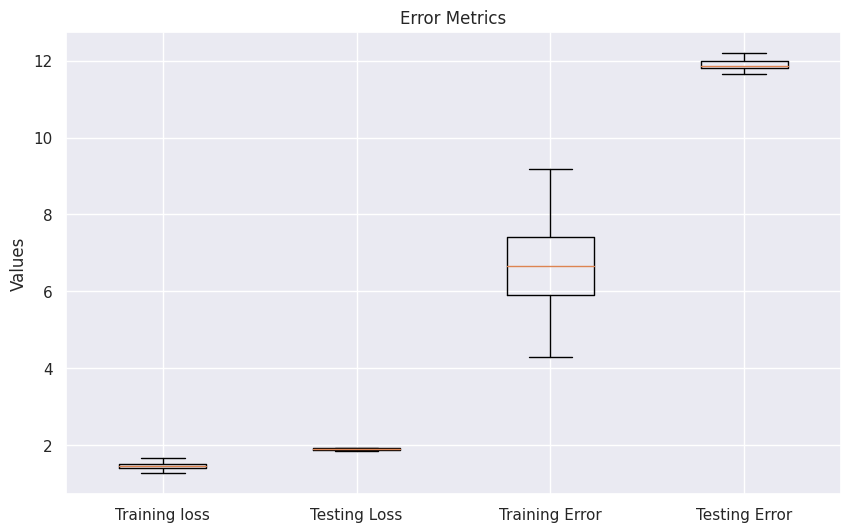

    Training Loss  Testing Loss  Mean Squared Training Error  \
1        1.369630      1.847957                     5.705221   
2        1.425155      1.914004                     6.385229   
3        1.658975      1.912889                     9.175399   
4        1.642410      1.910013                     9.022922   
5        1.378097      1.880223                     5.740662   
6        1.430153      1.899278                     6.357350   
7        1.488178      1.920438                     7.126522   
8        1.475134      1.849127                     6.950428   
9        1.276073      1.888251                     4.279874   
10       1.526299      1.905947                     7.505573   

    Mean Squared Testing Error  % of points in Confidence Interval  
1                    11.692756                                86.0  
2                    11.943201                                85.0  
3                    12.048312                                85.0  
4                  

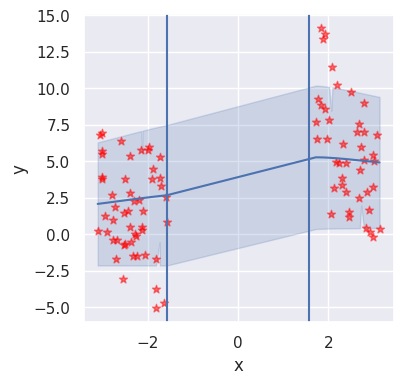

Number of data points within the 95% confidence interval: 80
Percentage of data points within the 95% confidence interval: 86.95652173913044


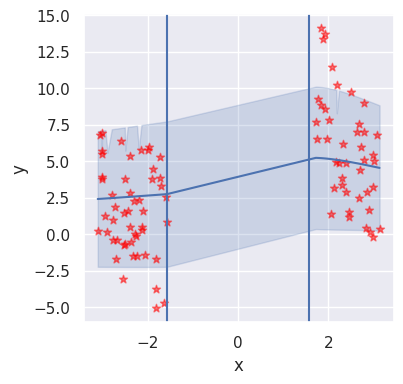

Number of data points within the 95% confidence interval: 79
Percentage of data points within the 95% confidence interval: 85.86956521739131


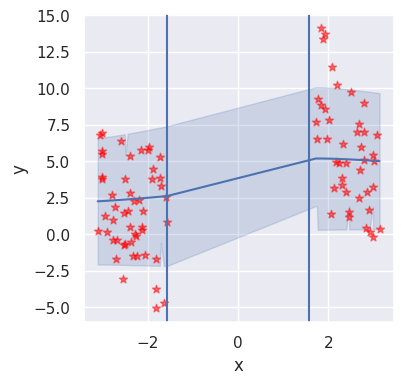

Number of data points within the 95% confidence interval: 78
Percentage of data points within the 95% confidence interval: 84.78260869565217


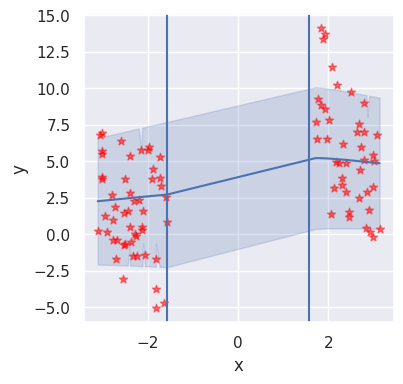

Number of data points within the 95% confidence interval: 79
Percentage of data points within the 95% confidence interval: 85.86956521739131


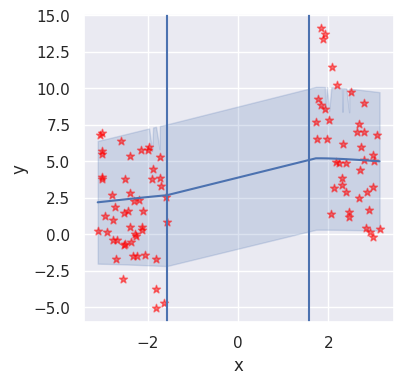

Number of data points within the 95% confidence interval: 80
Percentage of data points within the 95% confidence interval: 86.95652173913044


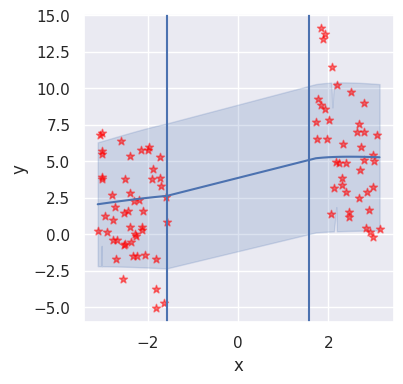

Number of data points within the 95% confidence interval: 79
Percentage of data points within the 95% confidence interval: 85.86956521739131


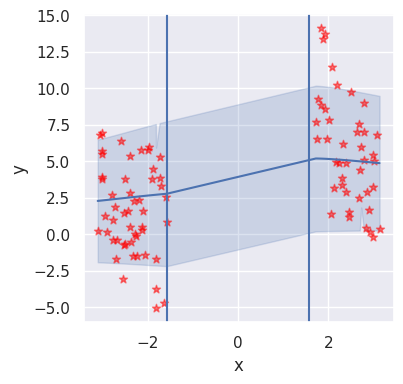

Number of data points within the 95% confidence interval: 78
Percentage of data points within the 95% confidence interval: 84.78260869565217


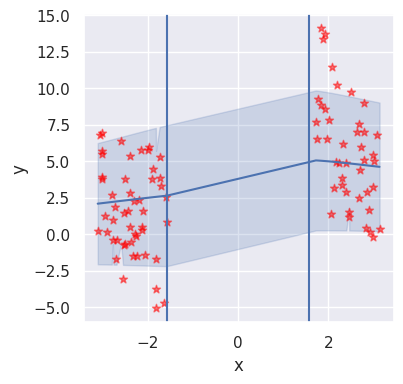

Number of data points within the 95% confidence interval: 77
Percentage of data points within the 95% confidence interval: 83.69565217391305


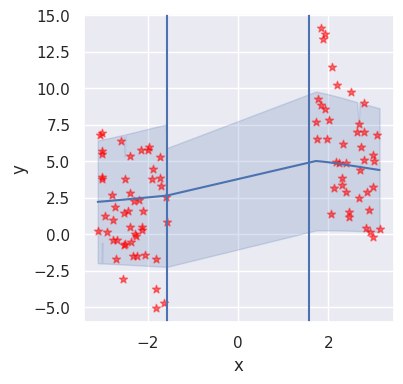

Number of data points within the 95% confidence interval: 78
Percentage of data points within the 95% confidence interval: 84.78260869565217


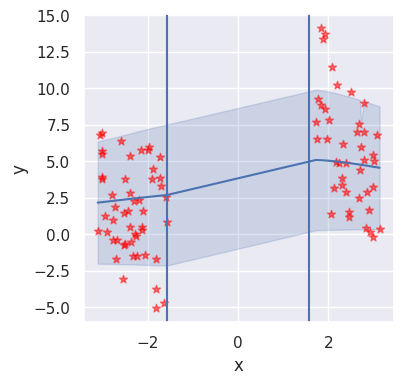

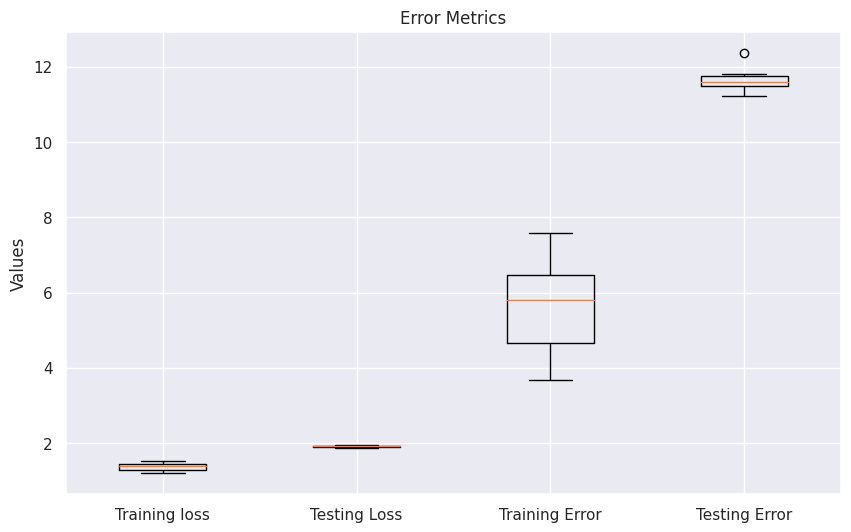

    Training Loss  Testing Loss  Mean Squared Training Error  \
1        1.394679      1.880773                     5.987743   
2        1.449736      1.876495                     6.589182   
3        1.207050      1.910034                     3.666976   
4        1.318432      1.911353                     5.014897   
5        1.365674      1.882167                     5.634430   
6        1.276149      1.952925                     4.412276   
7        1.401668      1.904924                     6.138373   
8        1.528511      1.894353                     7.595890   
9        1.280491      1.923867                     4.526884   
10       1.496750      1.924154                     7.189387   

    Mean Squared Testing Error  % of points in Confidence Interval  
1                    11.220293                           84.782609  
2                    11.713052                           86.956522  
3                    11.809556                           85.869565  
4                  

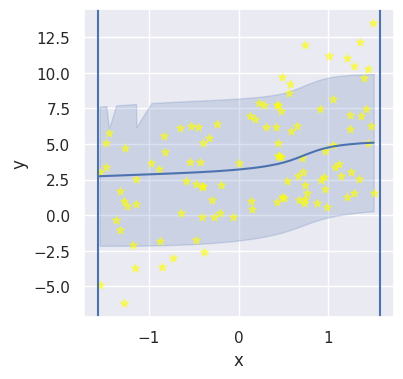

Number of data points within the 95% confidence interval: 93
Percentage of data points within the 95% confidence interval: 86.11111111111111


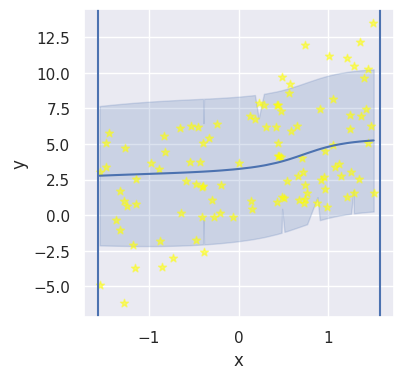

Number of data points within the 95% confidence interval: 93
Percentage of data points within the 95% confidence interval: 86.11111111111111


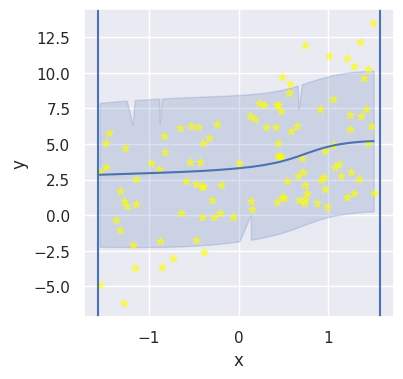

Number of data points within the 95% confidence interval: 93
Percentage of data points within the 95% confidence interval: 86.11111111111111


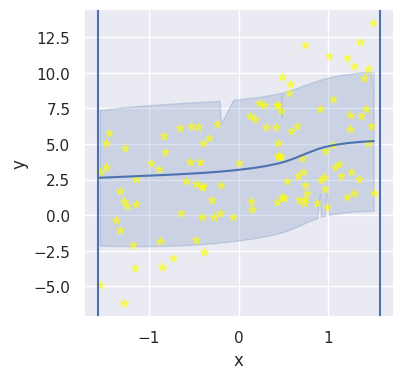

Number of data points within the 95% confidence interval: 93
Percentage of data points within the 95% confidence interval: 86.11111111111111


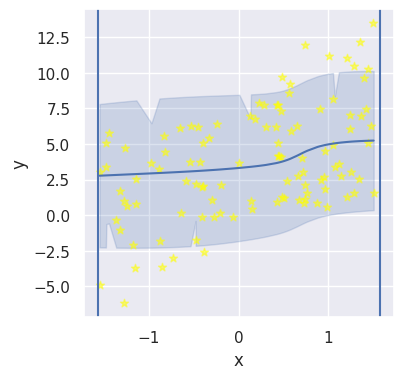

Number of data points within the 95% confidence interval: 93
Percentage of data points within the 95% confidence interval: 86.11111111111111


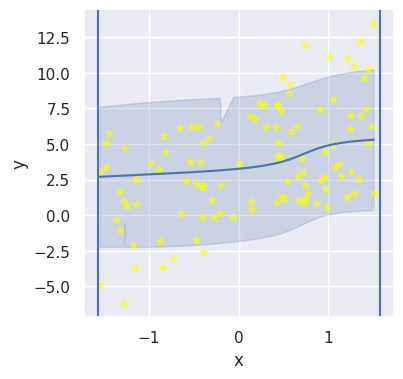

Number of data points within the 95% confidence interval: 93
Percentage of data points within the 95% confidence interval: 86.11111111111111


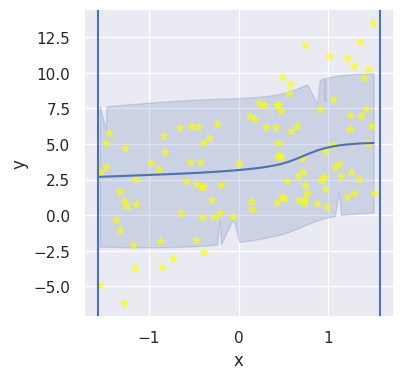

Number of data points within the 95% confidence interval: 93
Percentage of data points within the 95% confidence interval: 86.11111111111111


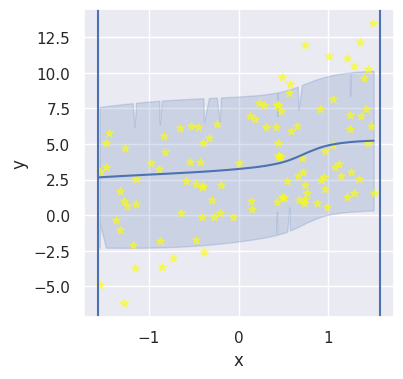

Number of data points within the 95% confidence interval: 93
Percentage of data points within the 95% confidence interval: 86.11111111111111


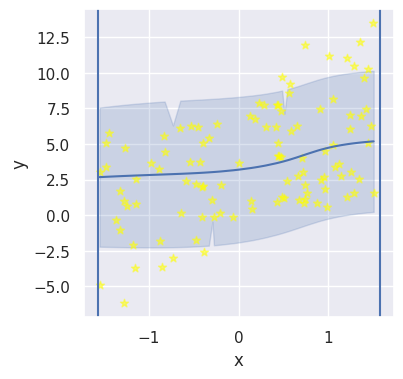

Number of data points within the 95% confidence interval: 93
Percentage of data points within the 95% confidence interval: 86.11111111111111


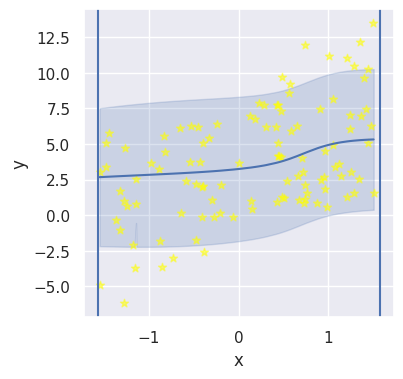

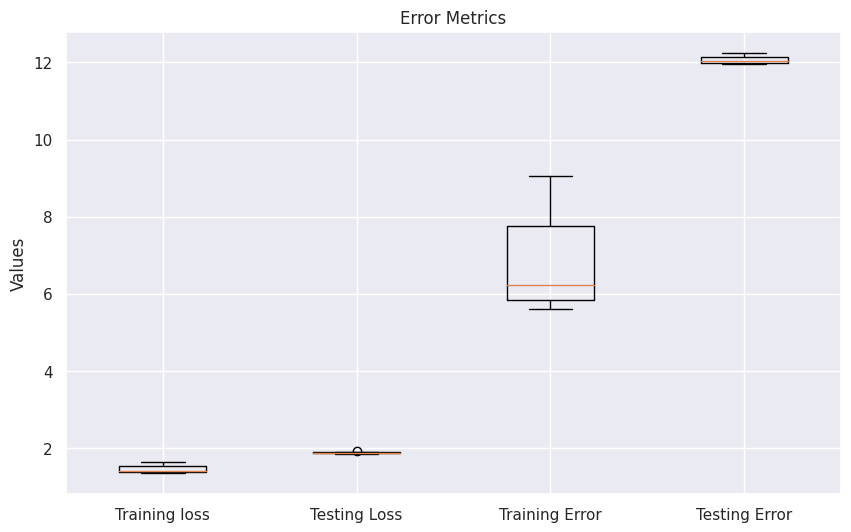

    Training Loss  Testing Loss  Mean Squared Training Error  \
1        1.564499      1.926274                     7.999137   
2        1.571064      1.869938                     8.244637   
3        1.386130      1.890039                     5.773228   
4        1.478810      1.893949                     7.043306   
5        1.645989      1.895364                     9.064869   
6        1.438628      1.906336                     6.518182   
7        1.389983      1.893666                     5.956193   
8        1.395249      1.866148                     5.911829   
9        1.379523      1.861477                     5.830231   
10       1.367237      1.890429                     5.599645   

    Mean Squared Testing Error  % of points in Confidence Interval  
1                    12.196865                           86.111111  
2                    11.967547                           86.111111  
3                    11.978957                           86.111111  
4                  

In [77]:
for tst_loader,tnsor_x_test,tnsor_y_test, col, x_test,y_test,output_dir, error_metric in zip(test_loaders,test_tensors_x,test_tensors_y,color,testset_x,testset_y,output_dirs,error_mets):
  train_losses=[]
  test_losses=[]
  errors_train=[]
  errors_test=[]
  percentages_count_within_ci=[]
  for i in range(10):
    net=SimpleNet()
    tr_loss,test_loss,mse_tr,mse_test,model,percentage_count_within_ci = Neural_Network(net,train_loader,test_loader_vars[tst_loader],tensor_x_mapping[tnsor_x_test],tensor_y_mapping[tnsor_y_test],testset_x_mapping[x_test],testset_y_mapping[y_test],col)
    error_metrics=tr_loss,test_loss,mse_tr,mse_test,model,percentage_count_within_ci
    model_filename = f"{output_dir}model_{i}.pkl"
    with open(model_filename, 'wb') as file:
      pickle.dump(error_metrics, file)
    train_losses.append(tr_loss)
    test_losses.append(test_loss)
    errors_train.append(mse_tr)
    errors_test.append(mse_test)
    percentages_count_within_ci.append(percentage_count_within_ci)
  # Extract numerical values from the tensors and remove grad_fn
  tr_loss_values= [tensor.item() for tensor in train_losses]
  test_loss_values=test_losses
  tr_errors_values= [tensor.item() for tensor in errors_train]
  test_errors_values= errors_test
  # Create a figure and axis
  fig, ax = plt.subplots(figsize=(10, 6))
  # Create box plots for each dataset
  box_plot_data = [tr_loss_values, test_loss_values, tr_errors_values, test_errors_values]
  box_labels = ['Training loss', 'Testing Loss', 'Training Error', 'Testing Error']
  ax.boxplot(box_plot_data, labels=box_labels)
  # Add labels and title
  ax.set_ylabel('Values')
  ax.set_title('Error Metrics')
  plt.savefig(f'snn_arch_{error_metric}.png', dpi=300)
  # Show the plot
  plt.show()

  mean_gaus_train_loss = np.mean(tr_loss_values)
  std_dev_gaus_train_loss = np.std(tr_loss_values)

  mean_gaus_test_loss = np.mean(test_loss_values)
  std_dev_gaus_test_loss = np.std(test_loss_values)

  mean_mse_train = np.mean(tr_errors_values)
  std_dev_mse_train = np.std(tr_errors_values)

  mean_mse_test = np.mean(test_errors_values)
  std_dev_mse_test = np.std(test_errors_values)

  mean_percentages_count_within_ci = np.mean(percentages_count_within_ci)
  std_dev_percentages_count_within_ci = np.std(percentages_count_within_ci)

  # Create a DataFrame from the lists
  data = {
    'Training Loss': tr_loss_values,
    'Testing Loss': test_loss_values,
    'Mean Squared Training Error': tr_errors_values,
    'Mean Squared Testing Error': test_errors_values,
    '% of points in Confidence Interval':percentages_count_within_ci,
  }

  num_columns = len(data)

  column_names = ['Training Loss','Testing Loss', 'Mean Squared Training Error','Mean Squared Testing Error','% of points in Confidence Interval']
  # Create a DataFrame with dynamic column names
  df = pd.DataFrame(data, columns=column_names)
  df.index += 1
  # Display the DataFrame as a table
  print(df)
  df.to_csv(f'snn_results_{error_metric}.txt', index=True)
  print('Mean of Gausiann Training Loss of 10 runs ', mean_gaus_train_loss)
  print('Standard Deviation of Gausiann Training Loss of 10 runs ' , std_dev_gaus_train_loss )

  print('Mean of Gausiann Testing Loss of 10 runs ',mean_gaus_test_loss )
  print('Standard Deviation of Gausiann Testing Loss of 10 runs ',std_dev_gaus_test_loss)

  print('Mean of MSE Training of 10 runs ',mean_mse_train)
  print('Standard Deviation of MSE Training of 10 runs ' , std_dev_mse_train)

  print('Mean of MSE Testing of 10 runs ',mean_mse_test )
  print('Standard Deviation of MSE Testing of 10 runs ', std_dev_mse_test)

  print('Mean of percentage of 95% conf interval for 10 runs in data',mean_percentages_count_within_ci)
  print('Standard Deviation of percentage of 95% conf interval for 10 runs in data ' , std_dev_percentages_count_within_ci)

  # File path
  file_path = f'snn_summary_{error_metric}.txt'

  # Open the file in write mode
  with open(file_path, 'w') as file:
    # Write the results to the file
    file.write('Mean of Gaussian Training Loss of 10 runs: {}\n'.format(mean_gaus_train_loss))
    file.write('Standard Deviation of Gaussian Training Loss of 10 runs: {}\n\n'.format(std_dev_gaus_train_loss))

    file.write('Mean of Gaussian Testing Loss of 10 runs: {}\n'.format(mean_gaus_test_loss))
    file.write('Standard Deviation of Gaussian Testing Loss of 10 runs: {}\n\n'.format(std_dev_gaus_test_loss))

    file.write('Mean of MSE Training of 10 runs: {}\n'.format(mean_mse_train))
    file.write('Standard Deviation of MSE Training of 10 runs: {}\n\n'.format(std_dev_mse_train))

    file.write('Mean of MSE Testing of 10 runs: {}\n'.format(mean_mse_test))
    file.write('Standard Deviation of MSE Testing of 10 runs: {}\n\n'.format(std_dev_mse_test))

    file.write('Mean of percentage of 95% conf interval for 10 runs in data {}\n'.format(mean_percentages_count_within_ci))
    file.write('Standard Deviation of percentage of 95% conf interval for 10 runs in data {}\n\n'.format(std_dev_percentages_count_within_ci))

  # Print a message indicating the file has been saved
  print(f'Results summary saved to {file_path}')
